Names: Aeden Rask, Diego McGrath

## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [2]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


The cross tabulation shows 94/388 participants survived in the Invasive group and 98/389 in the Conservative group. The estimated ATE is −0.01. Based on this point estimate alone, I would not choose the balloon pump, however, the difference is quite small and understanding the uncertainty could help make a better decision.

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [3]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

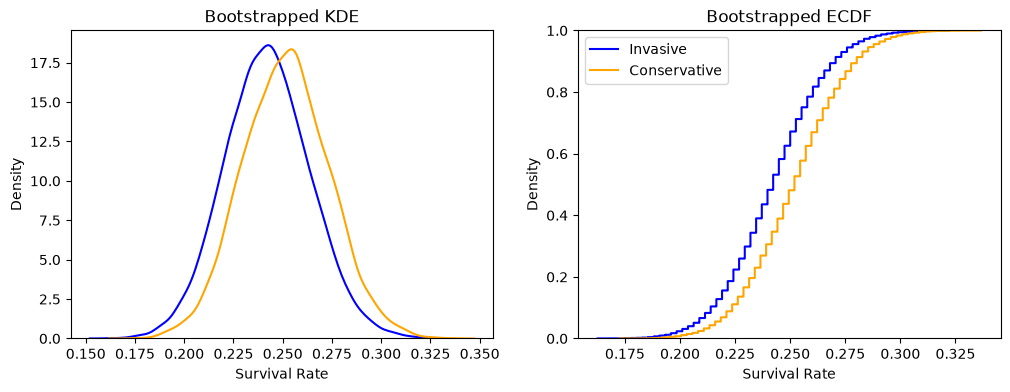

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

We see that there is a lot of overlap in the KDE, where their centers are only separated by a small amount. When looking at the ECDF, we see that Invasive treatments have a lower survival rate compared to Conservative. 

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

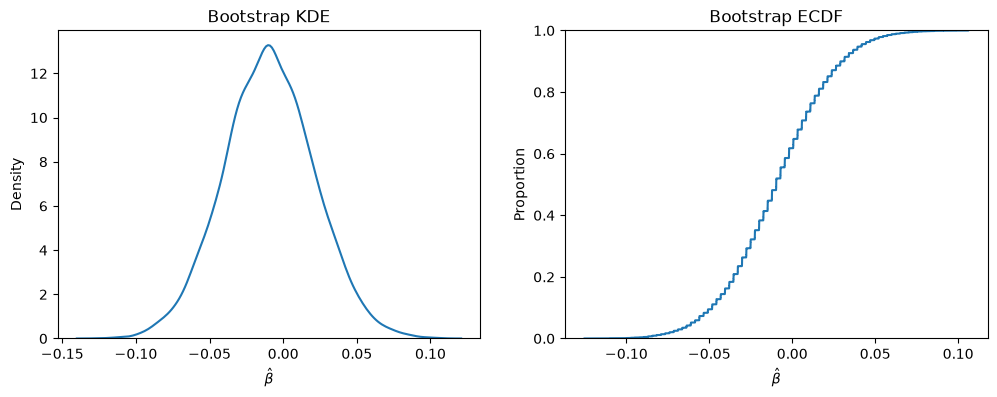

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


The KDE has a roughly bell shape, with a range of possible values from about -0.10 to 0.10

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [6]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06108711  0.04180061]
95% CI: [-0.06891862  0.05209647]
99% CI: [-0.08696499  0.07272812]


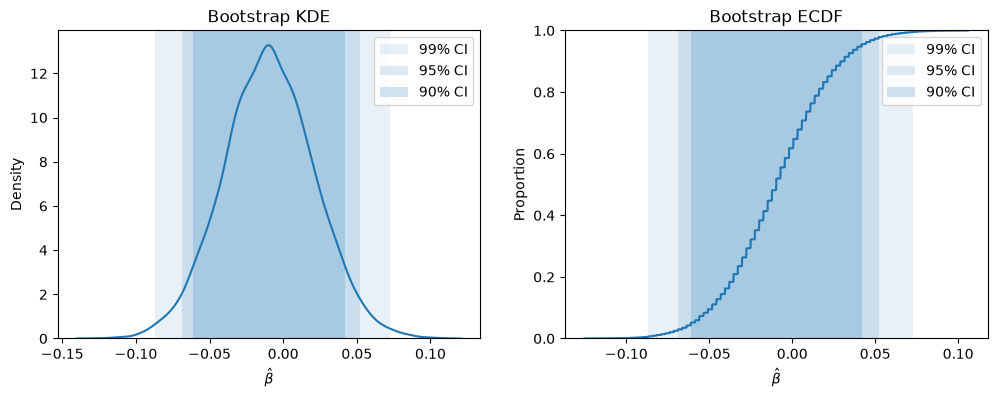

In [7]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

Zero is in all of the intervals listed out, and when looking at the 95% confidence interval to determine if we fail to reject the null, we still see zero in that interval, suggesting that we fail to reject the null hypothesis that the effect size is zero.

**6.** What have we learned about inserting balloons into hearts?

We initially learned that the Invasive group had a slightly lower observed survival rate than the Conservative group. Although, we wanted to double check this considering how small of a difference there was between the two groups using bootstrapping. When doing this, we see that 0 is included in the 95% confidence interval, suggesting that there is no clear evidence of a nonzero effect, and that we fail to reject the null hypothesis that the effect size is 0.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

## step 1

In [8]:
df = pd.read_csv('data/diabetes.csv')
df

,Unnamed: 0,treatment,outcome
0,1,met,success
1,2,rosi,failure
2,3,rosi,success
3,4,lifestyle,success
4,5,met,success
...,...,...,...
694,695,lifestyle,failure
695,696,lifestyle,success
696,697,lifestyle,success
697,698,met,success


In [9]:
# Cross-tabulate the outcomes for each treatment group
print(pd.crosstab(df["treatment"], df["outcome"]))

# Calculate the average outcome for each treatment group
print(df.groupby("treatment")["outcome"].apply(lambda x: (x == "success").mean()))

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143
treatment
lifestyle    0.534188
met          0.482759
rosi         0.613734
Name: outcome, dtype: float64


The average success rates are 53.4% for lifestyle, 48.3% for met, and 61.4% for rosi.

## step 2

In [10]:

R = 10_000

# Separate the three treatment groups
df_lifestyle = df.loc[df["treatment"] == "lifestyle", :]
df_met = df.loc[df["treatment"] == "met", :]
df_rosi = df.loc[df["treatment"] == "rosi", :]

# Store bootstrap estimates
outcome_lifestyle = []
outcome_met = []
outcome_rosi = []

# Store treatment effects
ate_met_rosi = []
ate_met_lifestyle = []
ate_rosi_lifestyle = []

for t in range(R):
    # Resample within each treatment arm
    df_lifestyle_t = df_lifestyle.sample(frac=1.0, replace=True)
    df_met_t = df_met.sample(frac=1.0, replace=True)
    df_rosi_t = df_rosi.sample(frac=1.0, replace=True)

    # Calculate the success rate in each group
    ol = (df_lifestyle_t["outcome"] == "success").mean()
    om = (df_met_t["outcome"] == "success").mean()
    or_ = (df_rosi_t["outcome"] == "success").mean()

    # Store the estimates
    outcome_lifestyle.append(ol)
    outcome_met.append(om)
    outcome_rosi.append(or_)
    
    # Calculate and store treatment effects
    ate_met_rosi.append(om - or_)
    ate_met_lifestyle.append(om - ol)
    ate_rosi_lifestyle.append(or_ - ol)

## step 3

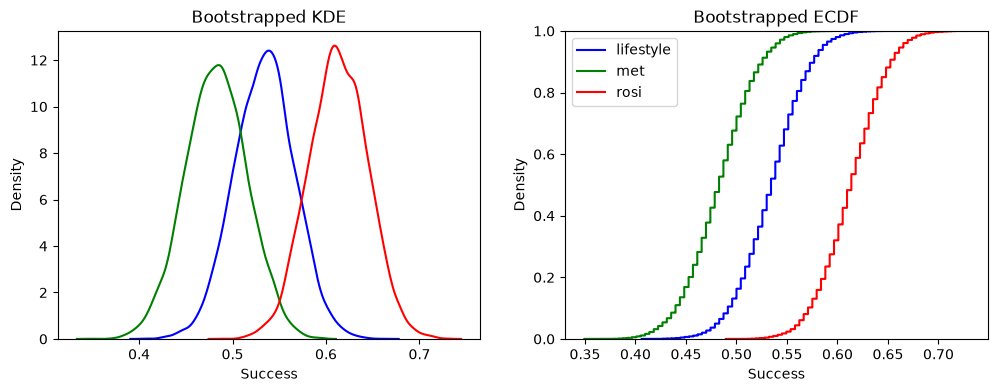

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_lifestyle, label='lifestyle', color='blue', ax=ax[0])
sns.kdeplot(outcome_met, label='met', color='green', ax=ax[0])
sns.kdeplot(outcome_rosi, label='rosi', color='red', ax=ax[0])

ax[0].set_xlabel("Success")
ax[0].set_ylabel("Density")
ax[0].set_title("Bootstrapped KDE")

sns.ecdfplot(outcome_lifestyle, label='lifestyle', color='blue', ax=ax[1])
sns.ecdfplot(outcome_met, label='met', color='green', ax=ax[1])
sns.ecdfplot(outcome_rosi, label='rosi', color='red', ax=ax[1])

ax[1].set_xlabel("Success")
ax[1].set_ylabel("Density")
ax[1].set_title("Bootstrapped ECDF")
ax[1].legend()

plt.legend()
plt.show()

In the KDE, we can see that there is some overlap, but the three peaks are pretty distinct. The ECDF indicates that met has the lowest success rate, followed by lifestyle, and rosi has the highest.

## step 4

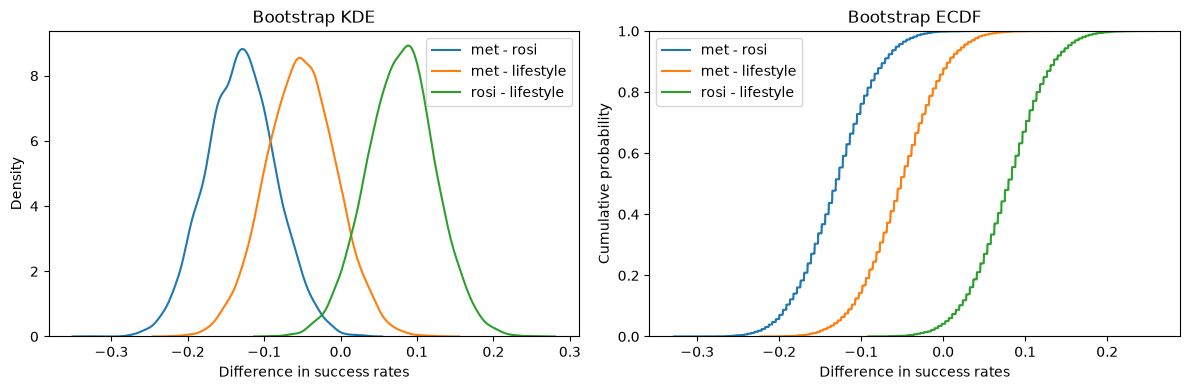

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# KDE
sns.kdeplot(ate_met_rosi, label="met - rosi", ax=ax[0])
sns.kdeplot(ate_met_lifestyle, label="met - lifestyle", ax=ax[0])
sns.kdeplot(ate_rosi_lifestyle, label="rosi - lifestyle", ax=ax[0])

ax[0].set_xlabel("Difference in success rates")
ax[0].set_ylabel("Density")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

# ECDF
sns.ecdfplot(ate_met_rosi, label="met - rosi", ax=ax[1])
sns.ecdfplot(ate_met_lifestyle, label="met - lifestyle", ax=ax[1])
sns.ecdfplot(ate_rosi_lifestyle, label="rosi - lifestyle", ax=ax[1])

ax[1].set_xlabel("Difference in success rates")
ax[1].set_ylabel("Cumulative probability")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

plt.tight_layout()
plt.show()

## step 5

In [13]:
for name, ate in [
    ("met - rosi", ate_met_rosi),
    ("met - lifestyle", ate_met_lifestyle),
    ("rosi - lifestyle", ate_rosi_lifestyle)
]:
    ci90 = np.quantile(ate, [0.05, 0.95])
    ci95 = np.quantile(ate, [0.025, 0.975])
    ci99 = np.quantile(ate, [0.005, 0.995])

    print(f"\n{name}")
    print(f"90% CI: {ci90}")
    print(f"95% CI: {ci95}")
    print(f"99% CI: {ci99}")


met - rosi
90% CI: [-0.20417715 -0.05364807]
95% CI: [-0.21712668 -0.04062454]
99% CI: [-0.24291485 -0.01478078]

met - lifestyle
90% CI: [-0.12861037  0.02579023]
95% CI: [-0.14179929  0.03886678]
99% CI: [-0.16755121  0.06878131]

rosi - lifestyle
90% CI: [0.00267782 0.1523972 ]
95% CI: [-0.01036279  0.16529108]
99% CI: [-0.03620557  0.1952057 ]


The 95% percentile bootstrap confidence intervals indicate a statistically significant difference between met and rosi because the interval for met − rosi, [−0.2212, −0.0407], does not contain zero. The intervals for met − lifestyle [−0.1417, 0.0387] and rosi − lifestyle [−0.0103, 0.1653] both contain zero, so these differences are not statistically significant at the 5% level.

Rosi appears to be the most effective intervention based on its observed success rate of 61.37%, compared with 53.42% for lifestyle and 48.28% for met. However, the confidence intervals do not establish that rosi is significantly more effective than lifestyle.